In [ ]:
%pip install qiskit pylatexenc --quiet

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector
import numpy as np
import math
import random
from IPython.display import display
import matplotlib.pyplot as plt
from OQMSA import OQMSA, plot_signed_amplitude

oqmsa = OQMSA()

## <u>**ORACLE: RULE 1**</u>

When d = 2^m - 1

O|D> = (e^(i.ϕ)|0><0| + |1><1|)⊕I(⊕m)

Example,

d = 7 = (0111)2

Oracle marks all elements 0000 to 0111 (mth bit is 0)

O|D> = (e^(i.ϕ)|0><0| + |1><1|)⊕I(⊕m)

=  e^(i.ϕ) (0000 + 0001 + ... + 0111) + 1000 + 1001 + ...

In [46]:
# Parameters
d = 2**2 - 1  # of the form 2^m - 1 for rule 1
m = math.ceil(math.log2(d+1))
phi = np.pi # changes the phase by pi that means marked target becomes (- target)

# Total qubits = m + 1
n_qubits = m + 1

In [47]:
# Create the oracle circuit
qc = QuantumCircuit(n_qubits)

# create an equal superposition
qc.h(range(n_qubits))
state_before = Statevector.from_instruction(qc)

In [48]:
print("d =", d)
print("Number of qubits =", n_qubits)

d = 3
Number of qubits = 3


In [49]:
state_before.draw("latex")

<IPython.core.display.Latex object>

In [50]:
oracle = QuantumCircuit(n_qubits, name="Oracle")

# Apply phase e^(i*phi) when the MSB is 0
msb = n_qubits - 1

oracle.x(msb) # converts msb 0 to 1
oracle.p(phi, msb)  # applies phase when msb is 1
oracle.x(msb) # converts msb 1 to 0

qc.compose(oracle, inplace=True)

# Get the state after the oracle
state_after = Statevector.from_instruction(qc)
state_after.draw("latex")

<IPython.core.display.Latex object>

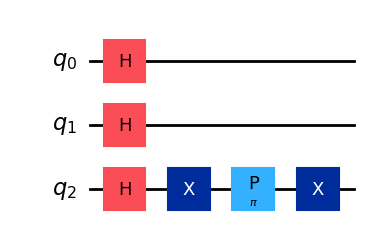

In [51]:
qc.draw("mpl")

## <u>**ORACLE: RULE 2**</u>

Example,

d = 35 = 2^5 + 2^2 - 1 = (100011)2

d + 1 = (100100)2

O|D> = (e^(i.ϕ)|0><0| + |1><1|)⊕I(⊕5)        .....// 6th digit is 0, i.e., 0 to 31

+|100><100| ⊕ (e^(i.ϕ)|0><0| + |1><1|)⊕I(⊕2)   .....// 3th digit is 0, i.e., 32 to 35

Hence, the above oracle marks 0 to 35.

In [52]:
d = 31
n_qubits = (d + 1).bit_length()
N = 2**n_qubits
M = d
t = 1 # 1 iteration
phi = phi = 2 * np.arcsin(np.sin(np.pi / np.sqrt(4 * t + 2)) * np.sqrt(M / N))

In [53]:
print("d =", d)
print("d + 1 =", d + 1)
print("Binary representation of d + 1 =", format(d + 1, f"0{n_qubits}b"))
print("Number of qubits =", n_qubits)
print("phi = ", phi)

d = 31
d + 1 = 32
Binary representation of d + 1 = 100000
Number of qubits = 6
phi =  1.4610411383094049


In [54]:
# Create an equal superposition
qc = QuantumCircuit(n_qubits)
qc.h(range(n_qubits))

state_before = Statevector.from_instruction(qc)
state_before.draw("latex")

<IPython.core.display.Latex object>

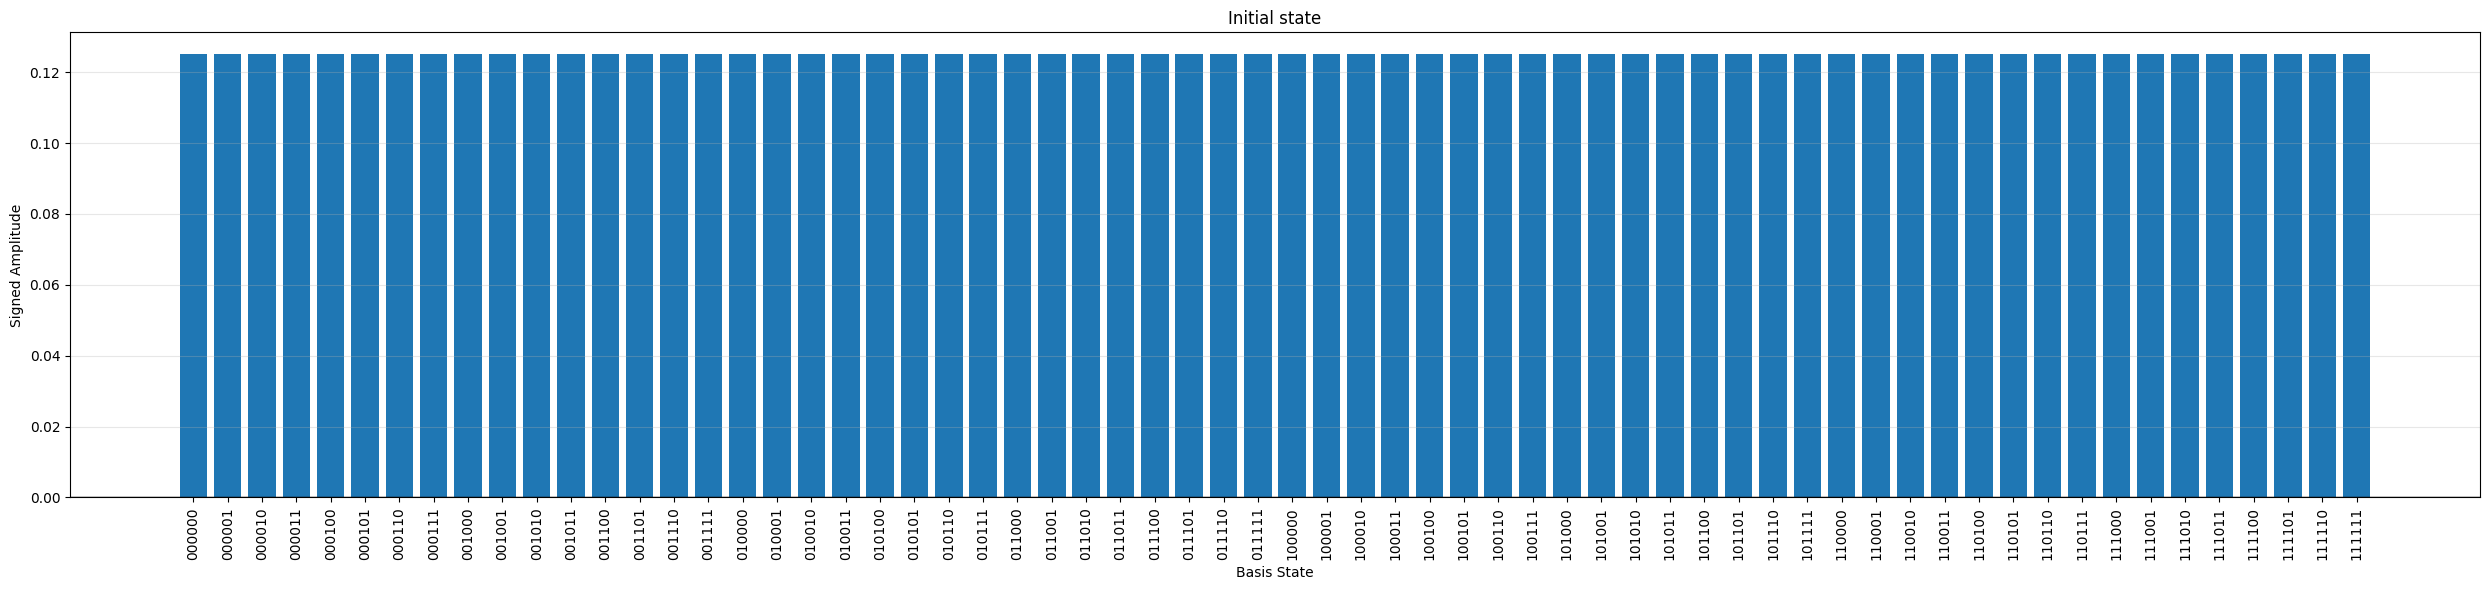

In [55]:
plot_signed_amplitude(state_before, "Initial state")

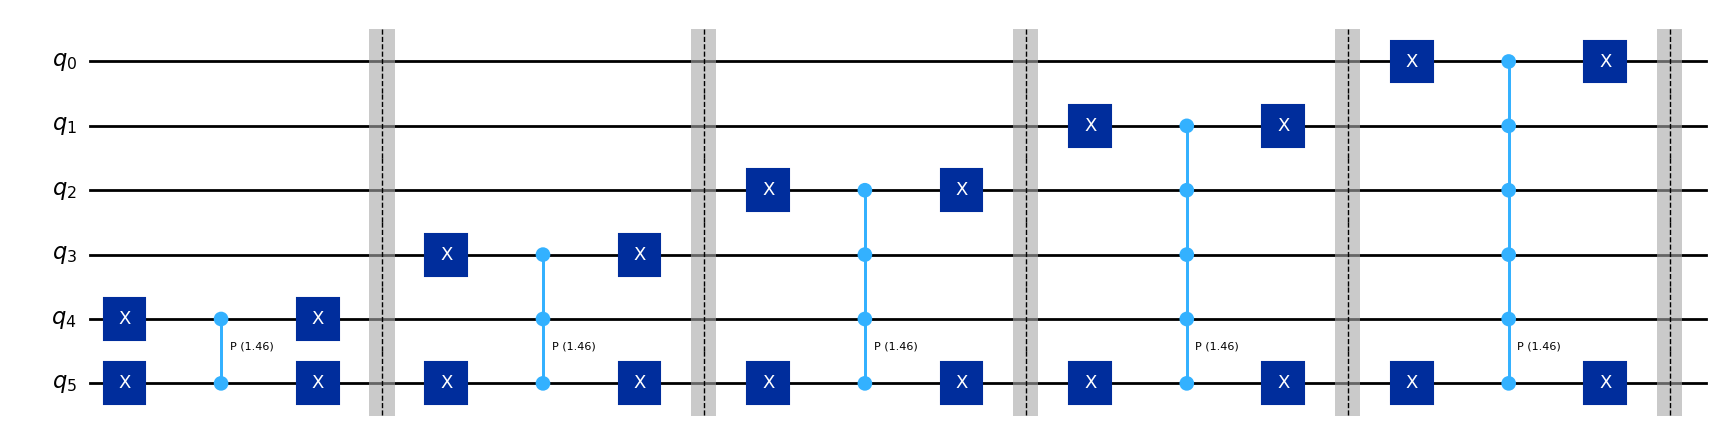

In [ ]:
oracle = oqmsa.oracle(n_qubits, d, phi)
oracle.draw("mpl")

In [58]:
# Apply the oracle
qc.compose(oracle, inplace=True)

# Get the state after the oracle
state_after_oracle = Statevector.from_instruction(qc)
state_after_oracle.draw("latex")

<IPython.core.display.Latex object>

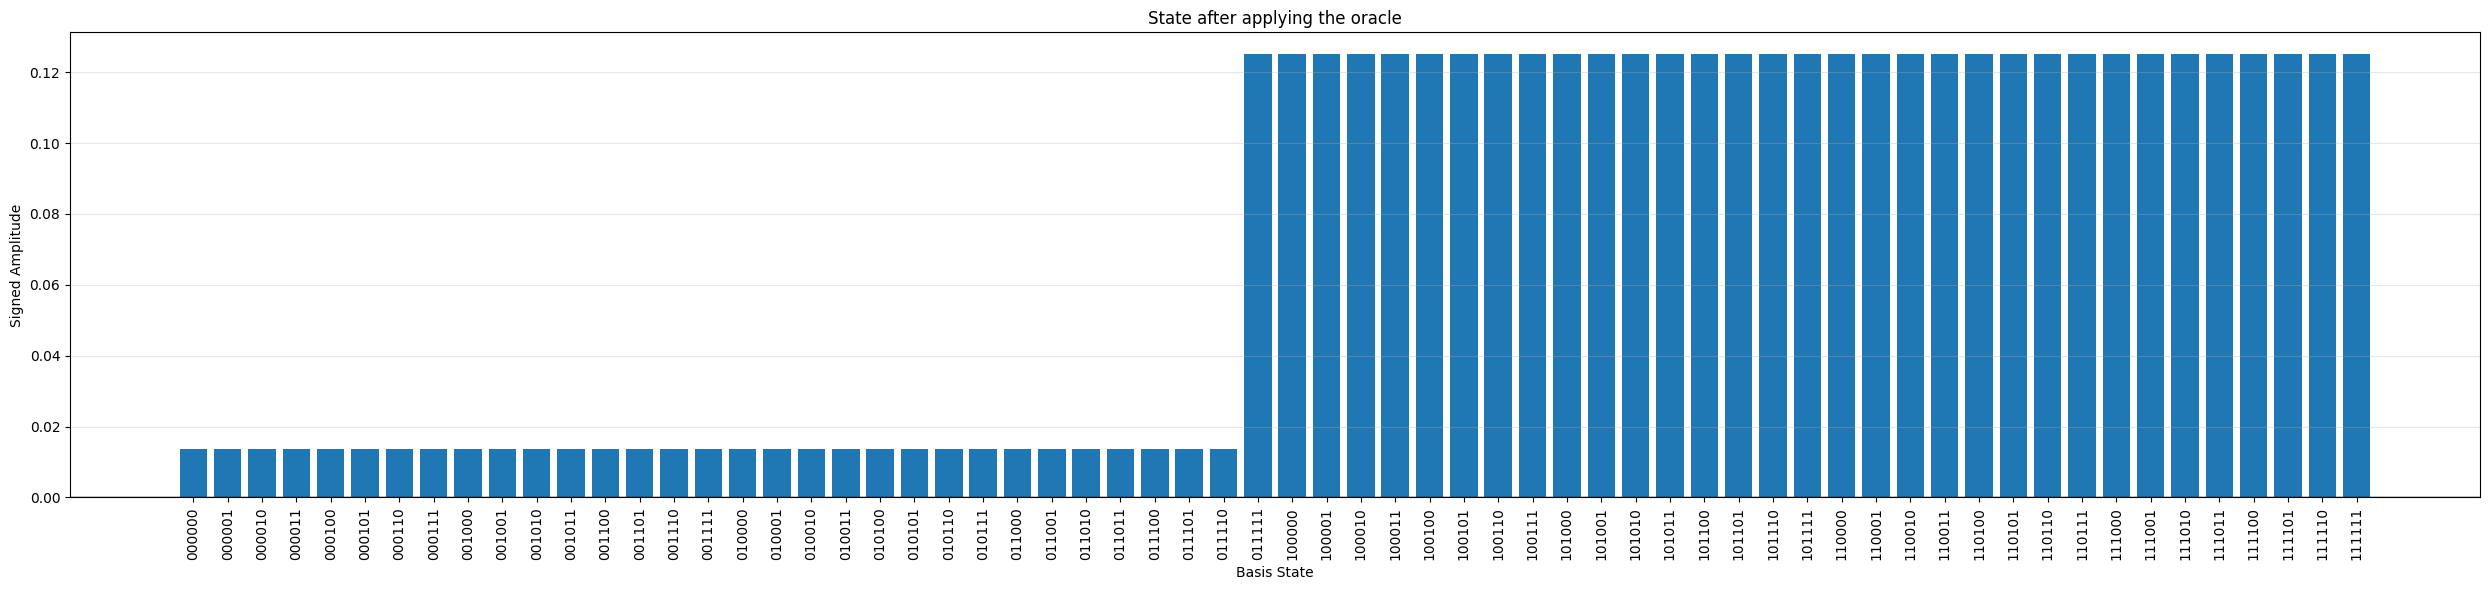

In [59]:
plot_signed_amplitude(state_after_oracle, "State after applying the oracle")

## <u>**DIFFUSER**</u>

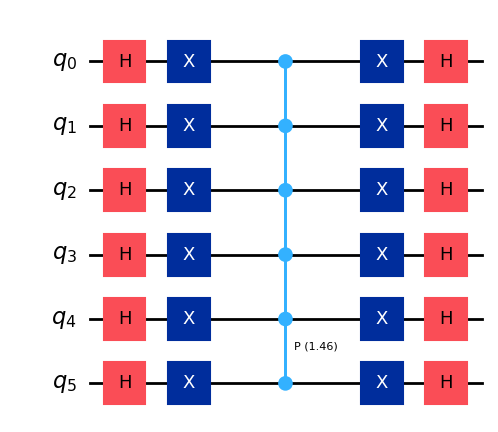

In [ ]:
diffuser = oqmsa.diffuser(n_qubits, phi)
diffuser.draw("mpl")

In [62]:
# Apply the oracle
qc.compose(diffuser, inplace=True)

# Get the state after the oracle
state_after_diffuser = Statevector.from_instruction(qc)
state_after_diffuser.draw("latex")

<IPython.core.display.Latex object>

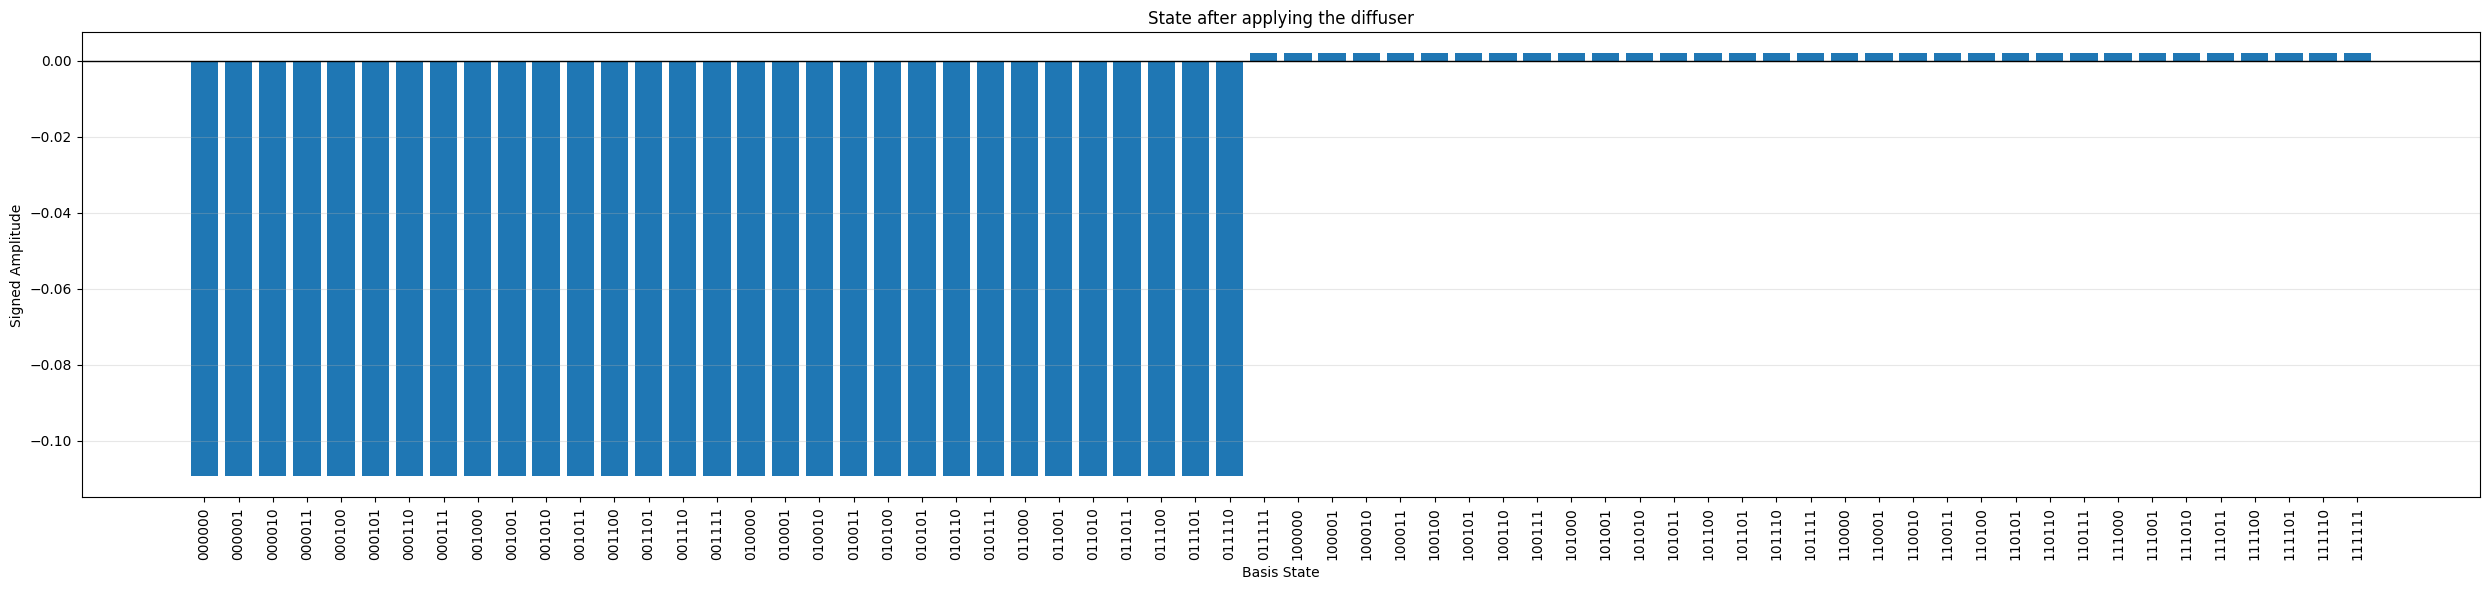

In [63]:
plot_signed_amplitude(state_after_diffuser, "State after applying the diffuser")

## <u>**OQMSA**</u>